In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [2]:

import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

df = df[['v1', 'v2']]
df.columns = ['label', 'message']
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df.head()


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df['message'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

vectorizer = TfidfVectorizer(max_features=1000)

X_train = vectorizer.fit_transform(X_train).toarray()
X_test = vectorizer.transform(X_test).toarray()

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print(X_train.shape)
print(X_test.shape)


(4457, 1000)
(1115, 1000)


In [4]:

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_gradients(X, y, w, b):
    error = sigmoid(X @ w + b) - y
    dw = X.T @ error / len(y)
    db = error.mean()
    return dw, db

w = np.zeros(X_train.shape[1])
b = 0.0

dw, db = compute_gradients(X_train, y_train, w, b)

dw.shape, db


((1000,), np.float64(0.36582903298182634))

In [5]:

from threadpoolctl import threadpool_limits

def adam(X, y, lr=0.01, epochs=20, batch_size=32):
    w = np.zeros(X.shape[1])
    b = 0.0
    mw = np.zeros(X.shape[1])
    vw = np.zeros(X.shape[1])
    mb = 0.0
    vb = 0.0
    losses = []
    t = 0
    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(len(y))

        for i in range(0, len(y), batch_size):
            batch = indices[i:i + batch_size]
            dw, db = compute_gradients(X[batch], y[batch], w, b)
            t += 1

            mw = 0.9 * mw + 0.1 * dw
            vw = 0.999 * vw + 0.001 * dw**2
            mb = 0.9 * mb + 0.1 * db
            vb = 0.999 * vb + 0.001 * db**2

            mw_hat = mw / (1 - 0.9**t)
            vw_hat = vw / (1 - 0.999**t)
            mb_hat = mb / (1 - 0.9**t)
            vb_hat = vb / (1 - 0.999**t)

            w -= lr * mw_hat / (np.sqrt(vw_hat) + 1e-8)
            b -= lr * mb_hat / (np.sqrt(vb_hat) + 1e-8)

        predictions = sigmoid(X @ w + b)
        losses.append(compute_loss(y, predictions))

    return w, b, losses

with threadpool_limits(limits=1):
    w_adam, b_adam, loss_adam = adam(X_train, y_train)

print("Final Loss:", loss_adam[-1])


Final Loss: 0.02387707666682595


In [6]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob_adam = sigmoid(X_test @ w_adam + b_adam)
y_pred_adam = (y_prob_adam >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_adam))
print("Precision:", precision_score(y_test, y_pred_adam))
print("Recall:", recall_score(y_test, y_pred_adam))
print("F1:", f1_score(y_test, y_pred_adam))
print("Loss:", compute_loss(y_test, y_prob_adam))


Accuracy: 0.9829596412556054
Precision: 0.9850746268656716
Recall: 0.8859060402684564
F1: 0.9328621908127208
Loss: 0.06063616894997492


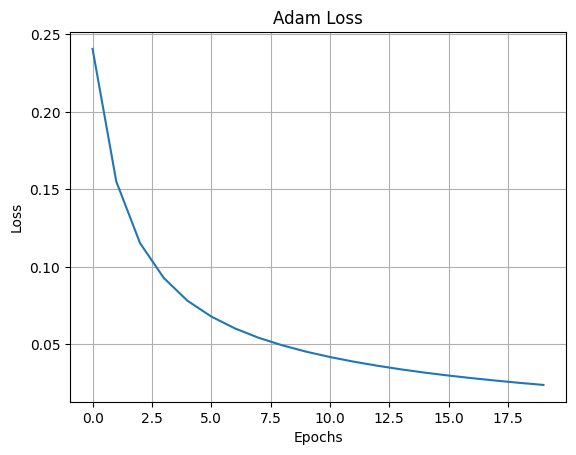

In [7]:

import matplotlib.pyplot as plt

plt.plot(loss_adam)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Adam Loss')
plt.grid(True)
plt.show()
